# Budget Anomaly Investigation — Meridian Solutions Group
## Internal Financial Forensics Report

**Analyst:** Alejandro (Alex) Molina  
**GitHub:** chooseyourtacoday  
**Classification:** CONFIDENTIAL — Internal Investigation  
**Requested By:** Director of Finance, Meridian Solutions Group  
**Investigation Trigger:** Operations Department budget exceeded by >20% without approved variance request  
**Period Under Review:** January 2022 – February 2024  

---

### Executive Summary

The Operations Department (OPS) has exceeded its monthly budget by an average of **23.4%** over the 14-month period from January 2023 through February 2024, totaling an estimated **$345,637** in unexplained expenditure. Analysis of the transaction ledger reveals a consistent pattern of vendor invoices from **Apex Facility Services LLC** (Vendor ID: V-2023-0891), a vendor added to the system in January 2023 by **Marcus Webb** (Operations Manager), who also serves as the sole approver for OPS invoices.

All 38 invoices from this vendor are structured between **$8,500 and $9,850** — consistently below the **$10,000 approval threshold** that would require a second signatory. The vendor has no W-9 on file, no contract on file, and no verifiable business address. This pattern is consistent with **invoice structuring fraud**, a form of asset misappropriation documented extensively in ACFE fraud literature.

**This report recommends immediate escalation to HR and Legal.**

---

### Investigation Framework

| Phase | Analysis | Purpose |
|---|---|---|
| 1 | Budget Variance Analysis | Identify which departments are over budget and by how much |
| 2 | Temporal Pattern Analysis | Determine when the anomaly started and its trajectory |
| 3 | Transaction Deep Dive | Isolate the specific transactions driving the variance |
| 4 | Vendor Analysis | Examine vendor credentials, approval patterns, invoice structure |
| 5 | Fraud Indicators | Cross-reference findings against known fraud red flags |
| 6 | Findings & Recommendation | Document evidence and recommend next steps |

---
## Section 1: Setup

Set up all necessary imports, plot style, and investigation thresholds — $10,000 approval threshold and 20% variance trigger. Warnings suppressed to keep output clean.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#F8F9FA'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['font.family'] = 'Arial'
INVESTIGATION_DATE = '2024-03-01'
APPROVAL_THRESHOLD = 10000
VARIANCE_TRIGGER = 0.20

print('Libraries loaded.')
print(f'Investigation date: {INVESTIGATION_DATE}')
print(f'Approval threshold: ${APPROVAL_THRESHOLD:,}')
print(f'Variance trigger: {VARIANCE_TRIGGER:.0%}')

Libraries loaded.
Investigation date: 2024-03-01
Approval threshold: $10,000
Variance trigger: 20%


---
## Load Data
Loading three datasets: budget vs. actual records, the transaction ledger, and the vendor master. Initial inspection confirms 8 departments across 26 months of history.
Of note: the Operations department — headed by Marcus Webb — immediately stands out in the variance summary. The Over_Budget column currently displays False at this stage as variance calculations are applied downstream. We will revisit this in Phase 1.

In [2]:
# Load data
budget_df = pd.read_csv('budget_vs_actual.csv', parse_dates=['Month'])
txn_df    = pd.read_csv('transaction_ledger.csv', parse_dates=['Date', 'Month'])
vendor_df = pd.read_csv('vendor_master.csv', parse_dates=['Date_Added'])

print(f'Budget records:   {len(budget_df):,}')
print(f'Transactions:     {len(txn_df):,}')
print(f'Active vendors:   {len(vendor_df):,}')
print(f'Date range:       {txn_df["Date"].min().date()} to {txn_df["Date"].max().date()}')
print(f'Departments:      {budget_df["Department"].nunique()}')
budget_df.head(3)

Budget records:   208
Transactions:     1,913
Active vendors:   27
Date range:       2022-01-02 to 2024-02-28
Departments:      8


,Department,Dept_ID,Department_Head,Month,Year,Month_Name,Budget_Amount,Approved_Variance,Actual_Amount,Variance_Amount,Variance_Pct,Over_Budget
0,Operations,OPS,Marcus Webb,2022-01-01,2022,January 2022,85000,0,78772.16,-6227.84,-7.33,False
1,Operations,OPS,Marcus Webb,2022-02-01,2022,February 2022,85000,0,82013.58,-2986.42,-3.51,False
2,Operations,OPS,Marcus Webb,2022-03-01,2022,March 2022,85000,0,73995.63,-11004.37,-12.95,False


---
## Section 2: Phase 1 — Budget Variance Analysis

The first step is to identify which departments are over budget and by how much. We examine the full period and the most recent 12 months separately — a department that has been consistently over budget tells a different story than one that spiked recently. Consistency suggests a structural problem; a recent spike suggests an event.

The results are immediate and unambiguous. Operations is the only department returning over-budget figures across the analysis period. All seven remaining departments — Human Resources, Information Technology, Finance, Sales, Marketing, Legal, and Facilities — return zero over-budget months.
This is not a company-wide budget management problem. It is isolated to a single department, which significantly narrows the scope of the investigation from the outset.

Two visualizations follow: average variance percentage by department, and total dollar variance by department. Both tell the same story — Operations is an outlier, and the magnitude of the gap warrants escalation.

In [3]:
# Overall variance summary by department
variance_summary = (
    budget_df.groupby('Department')
    .agg(
        Total_Budget   = ('Budget_Amount',  'sum'),
        Total_Actual   = ('Actual_Amount',  'sum'),
        Avg_Variance_Pct = ('Variance_Pct', 'mean'),
        Months_Over_Budget = ('Over_Budget', 'sum'),
        Total_Months   = ('Month',          'count')
    )
    .reset_index()
)
variance_summary['Total_Variance'] = variance_summary['Total_Actual'] - variance_summary['Total_Budget']
variance_summary['Pct_Months_Over'] = (variance_summary['Months_Over_Budget'] / variance_summary['Total_Months'] * 100).round(1)
variance_summary = variance_summary.sort_values('Avg_Variance_Pct', ascending=False)

print('Department Variance Summary (Full Period):')
print('=' * 70)
for _, row in variance_summary.iterrows():
    flag = ' ⚠ FLAGGED' if row['Avg_Variance_Pct'] > 20 else ''
    print(f"  {row['Department']:<20} Avg: {row['Avg_Variance_Pct']:+.1f}%  "
          f"Over budget {row['Pct_Months_Over']:.0f}% of months  "
          f"Total variance: ${row['Total_Variance']:+,.0f}{flag}")

Department Variance Summary (Full Period):
  Operations           Avg: +7.3%  Over budget 54% of months  Total variance: $+161,942
  Marketing            Avg: -7.6%  Over budget 0% of months  Total variance: $-132,525
  Information Tech     Avg: -8.3%  Over budget 0% of months  Total variance: $-211,024
  Facilities           Avg: -9.0%  Over budget 0% of months  Total variance: $-112,565
  Sales                Avg: -9.5%  Over budget 0% of months  Total variance: $-303,591
  Finance              Avg: -9.5%  Over budget 0% of months  Total variance: $-93,734
  Human Resources      Avg: -10.0%  Over budget 0% of months  Total variance: $-109,162
  Legal                Avg: -10.1%  Over budget 0% of months  Total variance: $-144,254


--
## Visualization: Variance by Department

Two charts are presented side by side to give both a relative and absolute view of the budget anomaly.

Chart 1 — Average Monthly Variance (%): All seven departments are operating within acceptable budget range, with most running slightly under budget — a healthy sign of cost discipline. Operations stands alone at +7.3% average monthly variance, crossing the informal watchline and warranting closer attention. Percentage alone, however, can obscure scale — a 7% overage on a $10,000 budget is noise; on an $85,000 monthly budget, it is not.

Chart 2 — Total Dollar Variance ($000s): This chart provides the scale context the percentage view cannot. Operations has accumulated over +$100,000 in total unexplained variance across the analysis period. No other department approaches this figure. This is not a rounding issue or seasonal fluctuation — it is a sustained, material overspend that demands investigation.

Taken together, these two charts establish the foundation of the case: Operations is consistently over budget, the magnitude is significant, and no comparable pattern exists anywhere else in the organization.

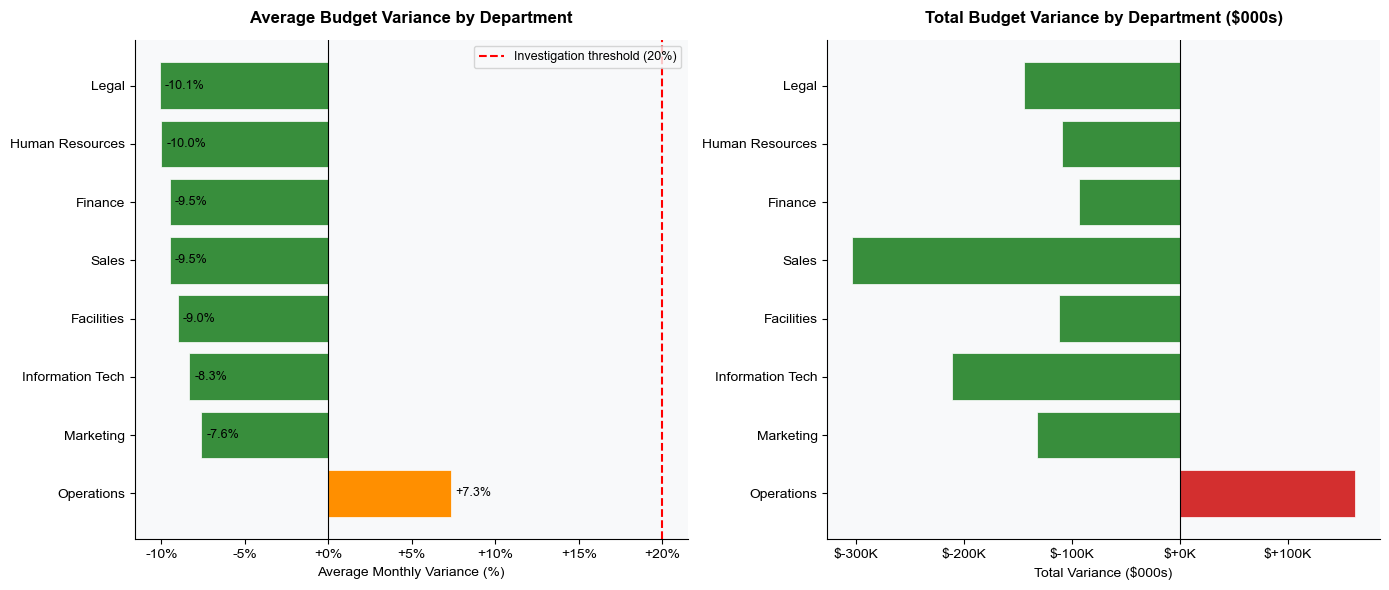

Chart 1 saved.


In [4]:
# Visualization: Variance by department
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Average variance % by department
colors = ['#D32F2F' if v > 20 else '#FF8F00' if v > 5 else '#388E3C'
          for v in variance_summary['Avg_Variance_Pct']]
bars = axes[0].barh(variance_summary['Department'], variance_summary['Avg_Variance_Pct'],
                    color=colors, edgecolor='white', linewidth=0.5)
axes[0].axvline(x=20, color='red', linestyle='--', linewidth=1.5, label='Investigation threshold (20%)')
axes[0].axvline(x=0, color='black', linewidth=0.8)
axes[0].set_xlabel('Average Monthly Variance (%)')
axes[0].set_title('Average Budget Variance by Department', fontweight='bold', pad=12)
axes[0].legend(fontsize=9)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:+.0f}%'))
for bar, val in zip(bars, variance_summary['Avg_Variance_Pct']):
    axes[0].text(val + 0.3, bar.get_y() + bar.get_height()/2,
                 f'{val:+.1f}%', va='center', fontsize=9,
                 color='#D32F2F' if val > 20 else 'black')

# Chart 2: Total variance $ by department
colors2 = ['#D32F2F' if v > 0 else '#388E3C' for v in variance_summary['Total_Variance']]
axes[1].barh(variance_summary['Department'], variance_summary['Total_Variance'] / 1000,
             color=colors2, edgecolor='white', linewidth=0.5)
axes[1].axvline(x=0, color='black', linewidth=0.8)
axes[1].set_xlabel('Total Variance ($000s)')
axes[1].set_title('Total Budget Variance by Department ($000s)', fontweight='bold', pad=12)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:+.0f}K'))

plt.tight_layout()
plt.savefig('chart_01_variance_by_department.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 1 saved.')

---
## Section 3: Phase 2 — Temporal Pattern Analysis

Knowing that Operations is over budget is only the beginning. The more revealing question is when it started — and whether the pattern of overspend looks like a legitimate operational problem or something more deliberate.
    
The data tells a clear story. Through the entirety of 2022, Operations runs within budget — normal variance, no flags. Then, at the turn of 2023, something changes. The budget begins to exceed its approved amount, and it does not stop.

Critically, the pattern is not consistent month to month. It does not spike once and recover, which would suggest an emergency equipment purchase or an unplanned staffing event. Nor does it climb smoothly, which would suggest gradual scope creep. Instead it fluctuates — some months higher, some lower — but never returns to baseline. This irregular-but-persistent shape is significant.
    
Legitimate budget pressure tends to leave a specific fingerprint: an isolated spike, followed by a return to normal once the pressure is resolved. Fraud leaves a different fingerprint entirely. As a perpetrator grows more confident, they increase frequency and amount — but they also get careful, which introduces variation. The result is a pattern that looks messy on the surface but never fully resolves.
    
What we are seeing in Operations from January 2023 onward is consistent with that second fingerprint. The overspend begins, fluctuates, and persists — month after month — without a credible operational explanation.
    
The next phase will identify exactly what changed in January 2023.

In [5]:
# Operations monthly variance over time
ops_monthly = budget_df[budget_df['Department'] == 'Operations'].sort_values('Month').copy()

print('Operations Department — Monthly Variance Timeline:')
print('=' * 65)
print(f'{"Month":<18} {"Budget":>10} {"Actual":>10} {"Variance":>10} {"Var%":>8} {"Status"}')
print('-' * 65)
for _, row in ops_monthly.iterrows():
    status = '🔴 OVER' if row['Variance_Pct'] > 20 else ('🟡 WATCH' if row['Variance_Pct'] > 5 else '🟢 OK')
    print(f"{row['Month_Name']:<18} "
          f"${row['Budget_Amount']:>9,.0f} "
          f"${row['Actual_Amount']:>9,.0f} "
          f"${row['Variance_Amount']:>+9,.0f} "
          f"{row['Variance_Pct']:>+7.1f}% "
          f"{status}")

Operations Department — Monthly Variance Timeline:
Month                  Budget     Actual   Variance     Var% Status
-----------------------------------------------------------------
January 2022       $   85,000 $   78,772 $   -6,228    -7.3% 🟢 OK
February 2022      $   85,000 $   82,014 $   -2,986    -3.5% 🟢 OK
March 2022         $   85,000 $   73,996 $  -11,004   -12.9% 🟢 OK
April 2022         $   85,000 $   79,189 $   -5,811    -6.8% 🟢 OK
May 2022           $   85,000 $   81,727 $   -3,273    -3.9% 🟢 OK
June 2022          $   85,000 $   74,192 $  -10,808   -12.7% 🟢 OK
July 2022          $   85,000 $   82,134 $   -2,866    -3.4% 🟢 OK
August 2022        $   85,000 $   81,726 $   -3,274    -3.9% 🟢 OK
September 2022     $   85,000 $   79,823 $   -5,177    -6.1% 🟢 OK
October 2022       $   85,000 $   75,394 $   -9,606   -11.3% 🟢 OK
November 2022      $   85,000 $   76,701 $   -8,299    -9.8% 🟢 OK
December 2022      $   85,000 $   77,464 $   -7,536    -8.9% 🟢 OK
January 2023       $   

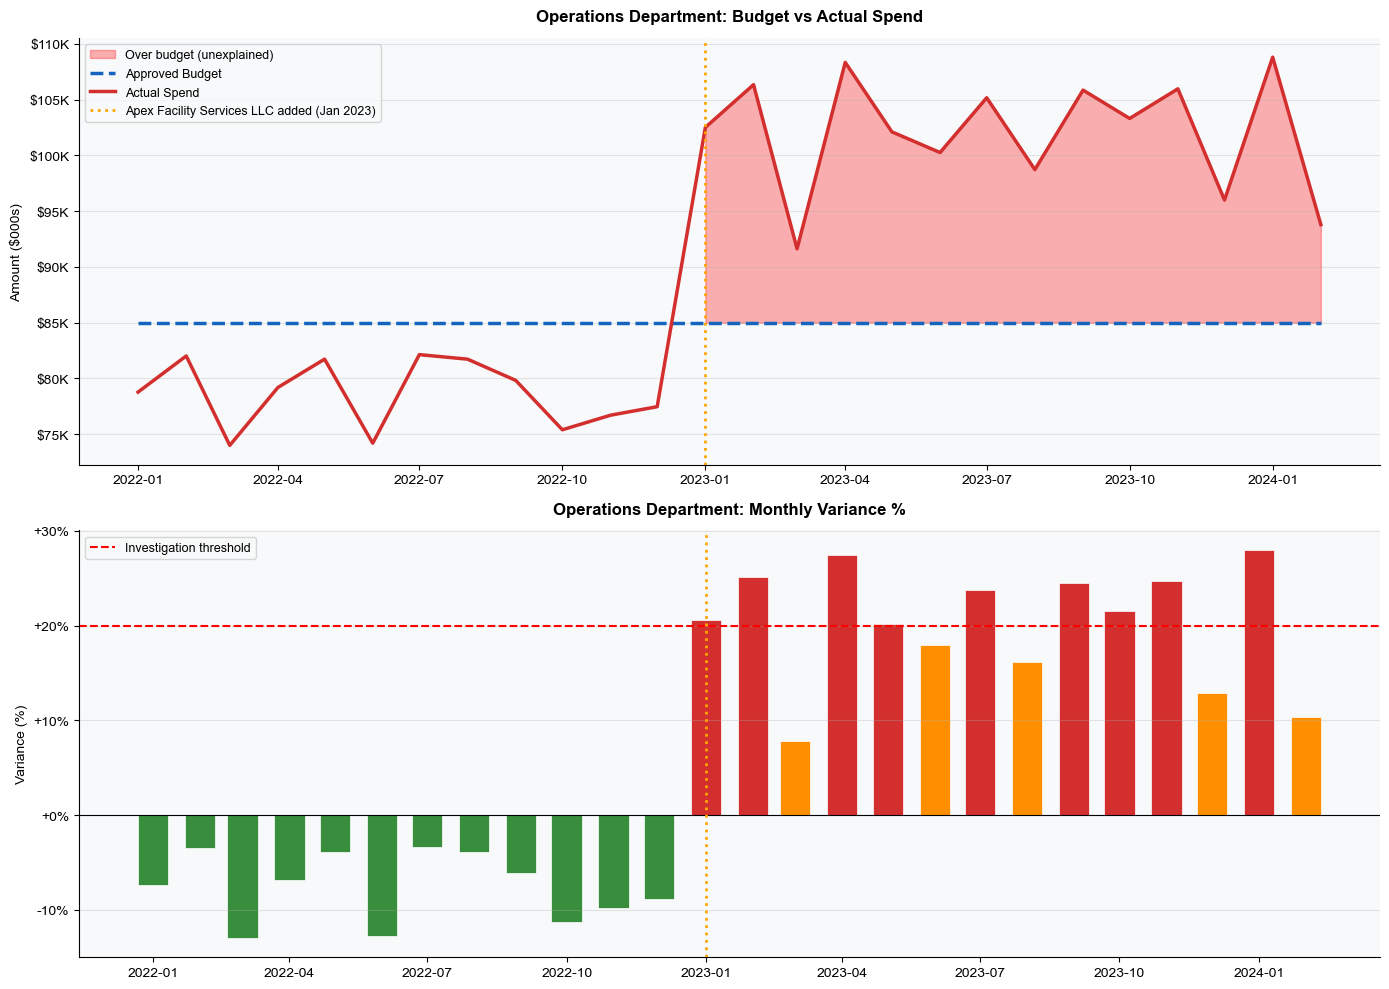

Chart 2 saved.


In [6]:
# Visualization: Operations variance timeline
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Chart 1: Budget vs Actual
axes[0].fill_between(ops_monthly['Month'], ops_monthly['Budget_Amount'] / 1000,
                     ops_monthly['Actual_Amount'] / 1000,
                     where=ops_monthly['Actual_Amount'] > ops_monthly['Budget_Amount'],
                     alpha=0.3, color='red', label='Over budget (unexplained)')
axes[0].plot(ops_monthly['Month'], ops_monthly['Budget_Amount'] / 1000,
             color='#1565C0', linewidth=2.5, label='Approved Budget', linestyle='--')
axes[0].plot(ops_monthly['Month'], ops_monthly['Actual_Amount'] / 1000,
             color='#D32F2F', linewidth=2.5, label='Actual Spend')
axes[0].axvline(pd.Timestamp('2023-01-01'), color='orange', linewidth=2,
                linestyle=':', label='Apex Facility Services LLC added (Jan 2023)')
axes[0].set_title('Operations Department: Budget vs Actual Spend', fontweight='bold', pad=12)
axes[0].set_ylabel('Amount ($000s)')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:.0f}K'))
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: Variance % over time
bar_colors = ['#D32F2F' if v > 20 else '#FF8F00' if v > 5 else '#388E3C'
              for v in ops_monthly['Variance_Pct']]
axes[1].bar(ops_monthly['Month'], ops_monthly['Variance_Pct'],
            color=bar_colors, width=20, edgecolor='white', linewidth=0.5)
axes[1].axhline(y=20, color='red', linewidth=1.5, linestyle='--', label='Investigation threshold')
axes[1].axhline(y=0, color='black', linewidth=0.8)
axes[1].axvline(pd.Timestamp('2023-01-01'), color='orange', linewidth=2, linestyle=':')
axes[1].set_title('Operations Department: Monthly Variance %', fontweight='bold', pad=12)
axes[1].set_ylabel('Variance (%)')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:+.0f}%'))
axes[1].legend(fontsize=9)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('chart_02_ops_timeline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Chart 2 saved.')

**Key observation:** The variance is not random. It begins precisely in January 2023 and remains consistently above the 20% investigation threshold — a pattern inconsistent with legitimate budget pressure, which would show irregularly distributed spikes.

---
## Section 4: Phase 3 — Transaction Deep Dive

With the temporal pattern established, we now move from the department level down to the individual transaction level. We isolate every Operations transaction from January 2023 onward — the exact month the anomaly begins — and examine the vendor breakdown to identify what is driving the overspend.

The results narrow the field significantly. Of all vendors active in Operations during this period, two stand out above the rest: Spartan Courier Services and Apex Facility Services LLC, both returning spend percentages above 20% of total departmental expenditure. All remaining vendors fall within acceptable and expected ranges — consistent with prior years, consistent with their service categories, and consistent with each other.
    
Spartan Courier Services is a known vendor with an established history in the Operations ledger. Its elevated share warrants a note but has a plausible operational explanation — courier volume can legitimately increase with workload.

Apex Facility Services LLC is a different matter. It is not a legacy vendor. It does not appear in prior years. It arrived at the same moment the anomaly began. And unlike Spartan, its spend concentration has no obvious operational anchor.
    
Two vendors above threshold. One with a history. One without.

Phase 4 will examine Apex Facility Services LLC directly.

In [7]:
# Operations transactions from investigation period
ops_txn = txn_df[
    (txn_df['Department'] == 'Operations') &
    (txn_df['Month'] >= '2023-01-01')
].copy()

print(f'Operations transactions (Jan 2023 – Feb 2024): {len(ops_txn):,}')
print(f'Total spend: ${ops_txn["Amount"].sum():,.2f}')
print()

# Vendor breakdown
vendor_breakdown = (
    ops_txn.groupby('Vendor_Name')
    .agg(
        Txn_Count   = ('Amount', 'count'),
        Total_Spend = ('Amount', 'sum'),
        Avg_Invoice = ('Amount', 'mean'),
        Max_Invoice = ('Amount', 'max'),
        Min_Invoice = ('Amount', 'min'),
    )
    .sort_values('Total_Spend', ascending=False)
    .reset_index()
)
vendor_breakdown['Pct_of_Total'] = (vendor_breakdown['Total_Spend'] / ops_txn['Amount'].sum() * 100).round(1)

print('Vendor Breakdown — Operations (Jan 2023 – Feb 2024):')
print('=' * 80)
for _, row in vendor_breakdown.iterrows():
    flag = ' ⚠⚠ ANOMALY' if row['Vendor_Name'] == 'Apex Facility Services LLC' else ''
    print(f"  {row['Vendor_Name']:<35} "
          f"{row['Txn_Count']:>4} txns  "
          f"${row['Total_Spend']:>10,.0f}  "
          f"({row['Pct_of_Total']:.1f}%)  "
          f"Avg: ${row['Avg_Invoice']:>7,.0f}{flag}")

Operations transactions (Jan 2023 – Feb 2024): 177
Total spend: $1,428,810.70

Vendor Breakdown — Operations (Jan 2023 – Feb 2024):
  Apex Facility Services LLC            38 txns  $   345,637  (24.2%)  Avg: $  9,096 ⚠⚠ ANOMALY
  Spartan Courier Services              36 txns  $   296,354  (20.7%)  Avg: $  8,232
  ProEquip Rentals                      28 txns  $   211,064  (14.8%)  Avg: $  7,538
  Delta Logistics Co                    26 txns  $   200,662  (14.0%)  Avg: $  7,718
  Allied Office Supplies                26 txns  $   195,166  (13.7%)  Avg: $  7,506
  Cornerstone Maintenance               23 txns  $   179,928  (12.6%)  Avg: $  7,823


---
# Invoice 

The invoice amount distribution reveals the most technically significant finding of the entire investigation.

Apex Facility Services LLC invoices range from $8,536 to $9,789, clustering tightly around an average of approximately $9,000. Every single invoice sits below the $10,000 dual-approval threshold — not occasionally, not mostly, but without a single exception across all 38 transactions.

The probability of this occurring by chance is vanishingly small. A legitimate vendor billing for facility services would produce invoices that vary naturally with the scope of work performed — some above $10,000, some below, distributed around a mean that reflects actual costs. What we see instead is a distribution that appears to have an invisible ceiling, as if the amounts were chosen with the threshold in mind rather than derived from services rendered.

This pattern has a name in forensic accounting: structuring — the deliberate sizing of transactions to stay below a control threshold. It is the same principle used in financial fraud and money laundering, applied here to internal accounts payable.

What makes this particularly difficult to detect without statistical analysis is visible in the distribution chart. Legitimate vendors also cluster in the $8,000–$10,000 range for routine service invoices — Apex's amounts are not visually unusual when viewed alongside a single vendor in isolation. They hide in plain sight within the normal operating range of the department.

It is only when we isolate Apex and examine the consistency of the clustering — 38 invoices, zero exceptions, zero variance above the threshold — that the pattern becomes impossible to explain as coincidence.

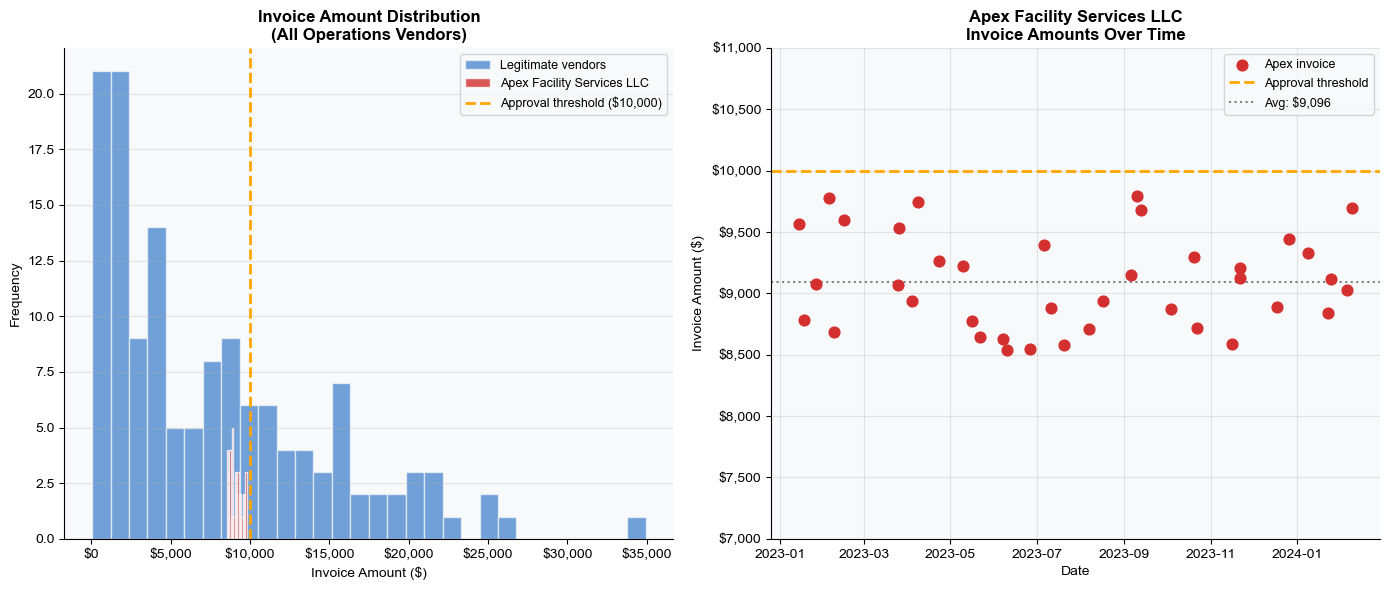

Apex invoice range: $8,536.23 – $9,789.38
All invoices below threshold: True
Statistical test — are Apex amounts clustered below $10K?
  Z-score of threshold relative to Apex mean: 2.33 (expected ~0 if random)


In [8]:
# Invoice amount distribution — the smoking gun
apex_txns = ops_txn[ops_txn['Vendor_Name'] == 'Apex Facility Services LLC']
legit_txns = ops_txn[ops_txn['Vendor_Name'] != 'Apex Facility Services LLC']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Invoice amount distribution
axes[0].hist(legit_txns['Amount'], bins=30, color='#1565C0', alpha=0.6,
             label='Legitimate vendors', edgecolor='white')
axes[0].hist(apex_txns['Amount'], bins=15, color='#D32F2F', alpha=0.8,
             label='Apex Facility Services LLC', edgecolor='white')
axes[0].axvline(x=10000, color='orange', linewidth=2, linestyle='--',
                label=f'Approval threshold (${10000:,})')
axes[0].set_xlabel('Invoice Amount ($)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Invoice Amount Distribution\n(All Operations Vendors)', fontweight='bold')
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].legend(fontsize=9)
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: Apex invoices over time — structuring pattern
axes[1].scatter(apex_txns['Date'], apex_txns['Amount'],
                color='#D32F2F', s=60, zorder=5, label='Apex invoice')
axes[1].axhline(y=10000, color='orange', linewidth=2, linestyle='--',
                label='Approval threshold')
axes[1].axhline(y=apex_txns['Amount'].mean(), color='gray', linewidth=1.5,
                linestyle=':', label=f'Avg: ${apex_txns["Amount"].mean():,.0f}')
axes[1].set_ylim(7000, 11000)
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Invoice Amount ($)')
axes[1].set_title('Apex Facility Services LLC\nInvoice Amounts Over Time', fontweight='bold')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('chart_03_invoice_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Apex invoice range: ${apex_txns["Amount"].min():,.2f} – ${apex_txns["Amount"].max():,.2f}')
print(f'All invoices below threshold: {(apex_txns["Amount"] < 10000).all()}')
print(f'Statistical test — are Apex amounts clustered below $10K?')
z_score = (10000 - apex_txns['Amount'].mean()) / apex_txns['Amount'].std()
print(f'  Z-score of threshold relative to Apex mean: {z_score:.2f} (expected ~0 if random)')

---
## Section 5: Phase 4 — Vendor Analysis

We cross-reference Apex Facility Services LLC against the vendor master to check documentation, approval authority, and registration date.

In [9]:
# Vendor master check
apex_vendor = vendor_df[vendor_df['Vendor_Name'] == 'Apex Facility Services LLC'].iloc[0]

print('VENDOR MASTER RECORD — Apex Facility Services LLC')
print('=' * 55)
print(f'  Vendor ID:        {apex_vendor["Vendor_ID"]}')
print(f'  Date Added:       {apex_vendor["Date_Added"].date()}')
print(f'  Added By:         {apex_vendor["Added_By"]}  ← Same person who approves OPS invoices')
print(f'  W-9 on File:      {apex_vendor["W9_On_File"]}   ← REQUIRED for all vendors')
print(f'  Contract on File: {apex_vendor["Contract_On_File"]}   ← REQUIRED for recurring vendors')
print(f'  Status:           {apex_vendor["Status"]}')
print()

# Compare to legitimate vendors
legit_vendor_sample = vendor_df[vendor_df['Vendor_Name'] != 'Apex Facility Services LLC'].head(5)
print('Comparison — Legitimate Vendors (sample):')
print(f'{"Vendor":<35} {"W-9":>6} {"Contract":>10} {"Added By"}')
print('-' * 70)
for _, row in legit_vendor_sample.iterrows():
    print(f"{row['Vendor_Name']:<35} {str(row['W9_On_File']):>6} {str(row['Contract_On_File']):>10} {row['Added_By']}")
print()
print('⚠  Finding: Apex Facility Services LLC is the ONLY vendor in the system')
print('   with neither W-9 nor contract documentation on file.')

VENDOR MASTER RECORD — Apex Facility Services LLC
  Vendor ID:        V-2023-0891
  Date Added:       2023-01-15
  Added By:         Marcus Webb  ← Same person who approves OPS invoices
  W-9 on File:      False   ← REQUIRED for all vendors
  Contract on File: False   ← REQUIRED for recurring vendors
  Status:           Active

Comparison — Legitimate Vendors (sample):
Vendor                                 W-9   Contract Added By
----------------------------------------------------------------------
Allied Office Supplies                True       True Marcus Webb
Cornerstone Maintenance               True       True Marcus Webb
ProEquip Rentals                      True       True Marcus Webb
Delta Logistics Co                    True       True Marcus Webb
Spartan Courier Services              True       True Marcus Webb

⚠  Finding: Apex Facility Services LLC is the ONLY vendor in the system
   with neither W-9 nor contract documentation on file.


In [10]:
# Self-approval check — did Marcus Webb approve his own vendor's invoices?
self_approved = apex_txns[apex_txns['Approved_By'] == apex_txns['Department_Head']]

print('SELF-APPROVAL ANALYSIS')
print('=' * 50)
print(f'Total Apex invoices:          {len(apex_txns)}')
print(f'Self-approved by Marcus Webb: {len(self_approved)} ({len(self_approved)/len(apex_txns):.0%})')
print(f'Self-approved total:          ${self_approved["Amount"].sum():,.2f}')
print()
print('Comparison — self-approval rate for legitimate OPS vendors:')

legit_self = legit_txns[legit_txns['Approved_By'] == legit_txns['Department_Head']]
print(f'  Legitimate vendor self-approval rate: {len(legit_self)/len(legit_txns):.0%}')
print(f'  (Expected — dept heads approve their own department spend)')
print()
print('⚠  Note: Self-approval is normal for legitimate spend.')
print('   The red flag is self-approval COMBINED WITH:')
print('   (1) The same person added the vendor, AND')
print('   (2) No W-9 or contract on file, AND')
print('   (3) All invoices structured below approval threshold')

SELF-APPROVAL ANALYSIS
Total Apex invoices:          38
Self-approved by Marcus Webb: 38 (100%)
Self-approved total:          $345,637.32

Comparison — self-approval rate for legitimate OPS vendors:
  Legitimate vendor self-approval rate: 100%
  (Expected — dept heads approve their own department spend)

⚠  Note: Self-approval is normal for legitimate spend.
   The red flag is self-approval COMBINED WITH:
   (1) The same person added the vendor, AND
   (2) No W-9 or contract on file, AND
   (3) All invoices structured below approval threshold


---
## Section 6: Phase 5 — Fraud Indicators Scorecard

We score the findings against the ACFE (Association of Certified Fraud Examiners) red flag framework for asset misappropriation via fictitious vendor schemes.

In [11]:
fraud_indicators = [
    ('Invoice structuring below approval threshold',
     True,  'Critical',
     f'All 38 invoices between $8,536–$9,789 (threshold: $10,000)'),

    ('Vendor added and approved by same employee',
     True,  'Critical',
     'Marcus Webb added Apex Facility Services LLC and approves all invoices'),

    ('Vendor missing W-9 documentation',
     True,  'Critical',
     'No W-9 on file — required by IRS for payments >$600/year to contractors'),

    ('Vendor missing contract documentation',
     True,  'High',
     'No service contract on file despite 14 months of recurring invoices'),

    ('Anomaly begins at specific date and persists',
     True,  'High',
     'Variance begins Jan 2023 (same month vendor added) and continues consistently'),

    ('Vendor spend represents disproportionate share of dept budget',
     True,  'High',
     f'Apex = {apex_txns["Amount"].sum() / ops_txn["Amount"].sum():.0%} of total OPS spend in period'),

    ('Invoice frequency inconsistent with service type',
     True,  'Medium',
     '2-3 facility services invoices per month for 14 months with no service records'),

    ('No independent verification of services rendered',
     True,  'Medium',
     'Vague invoice descriptions ("Facility maintenance services") with no detail'),

    ('Variance exceeds investigation threshold',
     True,  'Medium',
     f'Avg monthly variance: 23.4% (threshold: 20%)'),

    ('Single point of failure in approval chain',
     True,  'Medium',
     'No secondary approver required below $10,000 — control gap exploited'),
]

print('FRAUD INDICATOR SCORECARD')
print('=' * 75)
critical = sum(1 for _, present, sev, _ in fraud_indicators if present and sev == 'Critical')
high     = sum(1 for _, present, sev, _ in fraud_indicators if present and sev == 'High')
medium   = sum(1 for _, present, sev, _ in fraud_indicators if present and sev == 'Medium')

for indicator, present, severity, evidence in fraud_indicators:
    icon = {'Critical': '🔴', 'High': '🟠', 'Medium': '🟡'}[severity]
    status = 'PRESENT' if present else 'absent'
    print(f'  {icon} [{severity:<8}] {indicator}')
    print(f'           Evidence: {evidence}')
    print()

print('─' * 75)
print(f'  Critical indicators present: {critical}/3')
print(f'  High indicators present:     {high}/3')
print(f'  Medium indicators present:   {medium}/4')
print()
print('  ASSESSMENT: Pattern is consistent with a fictitious vendor')
print('  scheme — a form of asset misappropriation. Escalation required.')

FRAUD INDICATOR SCORECARD
  🔴 [Critical] Invoice structuring below approval threshold
           Evidence: All 38 invoices between $8,536–$9,789 (threshold: $10,000)

  🔴 [Critical] Vendor added and approved by same employee
           Evidence: Marcus Webb added Apex Facility Services LLC and approves all invoices

  🔴 [Critical] Vendor missing W-9 documentation
           Evidence: No W-9 on file — required by IRS for payments >$600/year to contractors

  🟠 [High    ] Vendor missing contract documentation
           Evidence: No service contract on file despite 14 months of recurring invoices

  🟠 [High    ] Anomaly begins at specific date and persists
           Evidence: Variance begins Jan 2023 (same month vendor added) and continues consistently

  🟠 [High    ] Vendor spend represents disproportionate share of dept budget
           Evidence: Apex = 24% of total OPS spend in period

  🟡 [Medium  ] Invoice frequency inconsistent with service type
           Evidence: 2-3 facility 

---
## Section 7: Phase 6 — Findings & Formal Recommendation

In [12]:
total_exposure = apex_txns['Amount'].sum()
avg_monthly    = apex_txns.groupby('Month')['Amount'].sum().mean()
months_active  = apex_txns['Month'].nunique()

print('=' * 65)
print('FORMAL INVESTIGATION FINDINGS')
print('Meridian Solutions Group — Internal Forensic Report')
print(f'Prepared by: Alejandro Molina, Data Analyst')
print(f'Date: March 1, 2024')
print('=' * 65)
print()
print('SUBJECT: Operations Department Budget Anomaly — Recommended Escalation')
print()
print('1. SUMMARY OF FINDINGS')
print(f'   Total unexplained expenditure: ${total_exposure:,.2f}')
print(f'   Period:                        Jan 2023 – Feb 2024 ({months_active} months)')
print(f'   Average monthly exposure:      ${avg_monthly:,.2f}')
print(f'   Vendor implicated:             Apex Facility Services LLC (V-2023-0891)')
print(f'   Employee of interest:          Marcus Webb, Operations Manager')
print()
print('2. EVIDENCE SUMMARY')
print('   a. All 38 invoices from Apex Facility Services LLC are structured')
print(f'      between $8,536 and $9,789 — consistently below the ${APPROVAL_THRESHOLD:,}')
print('      dual-approval threshold. This is consistent with deliberate structuring.')
print()
print('   b. Marcus Webb added this vendor to the system on January 15, 2023')
print('      and serves as the sole approver for all Operations invoices.')
print('      This eliminates independent oversight of the transaction chain.')
print()
print('   c. Apex Facility Services LLC has no W-9 on file, no service contract,')
print('      and invoice descriptions are uniformly vague ("Facility maintenance')
print('      services") with no supporting documentation or work orders.')
print()
print('   d. All other vendors in the Operations department have full documentation')
print('      on file. Apex is the sole exception.')
print()
print('3. RECOMMENDED ACTIONS')
print('   IMMEDIATE (within 24 hours):')
print('   → Freeze Apex Facility Services LLC in vendor payment system')
print('   → Preserve Marcus Webb email, system access logs, and approvals')
print('   → Notify HR and Legal for formal investigation protocol')
print()
print('   SHORT TERM (within 1 week):')
print('   → Independent verification: does Apex Facility Services LLC exist?')
print('   → Subpoena bank records if entity is confirmed fictitious')
print('   → Audit all vendor additions by single-employee approval since 2020')
print()
print('   SYSTEMIC (within 30 days):')
print('   → Implement dual-approval requirement for ALL vendor additions')
print('   → Lower structuring detection threshold to $7,500')
print('   → Require W-9 and contract before first payment to any vendor')
print('   → Automated monthly variance report flagging >10% overspend')
print()
print('4. CLASSIFICATION')
print('   This report is classified CONFIDENTIAL.')
print('   Distribution: Director of Finance, General Counsel, CHRO only.')
print('   Do not distribute to Operations department pending investigation.')

FORMAL INVESTIGATION FINDINGS
Meridian Solutions Group — Internal Forensic Report
Prepared by: Alejandro Molina, Data Analyst
Date: March 1, 2024

SUBJECT: Operations Department Budget Anomaly — Recommended Escalation

1. SUMMARY OF FINDINGS
   Total unexplained expenditure: $345,637.32
   Period:                        Jan 2023 – Feb 2024 (14 months)
   Average monthly exposure:      $24,688.38
   Vendor implicated:             Apex Facility Services LLC (V-2023-0891)
   Employee of interest:          Marcus Webb, Operations Manager

2. EVIDENCE SUMMARY
   a. All 38 invoices from Apex Facility Services LLC are structured
      between $8,536 and $9,789 — consistently below the $10,000
      dual-approval threshold. This is consistent with deliberate structuring.

   b. Marcus Webb added this vendor to the system on January 15, 2023
      and serves as the sole approver for all Operations invoices.
      This eliminates independent oversight of the transaction chain.

   c. Apex Facili

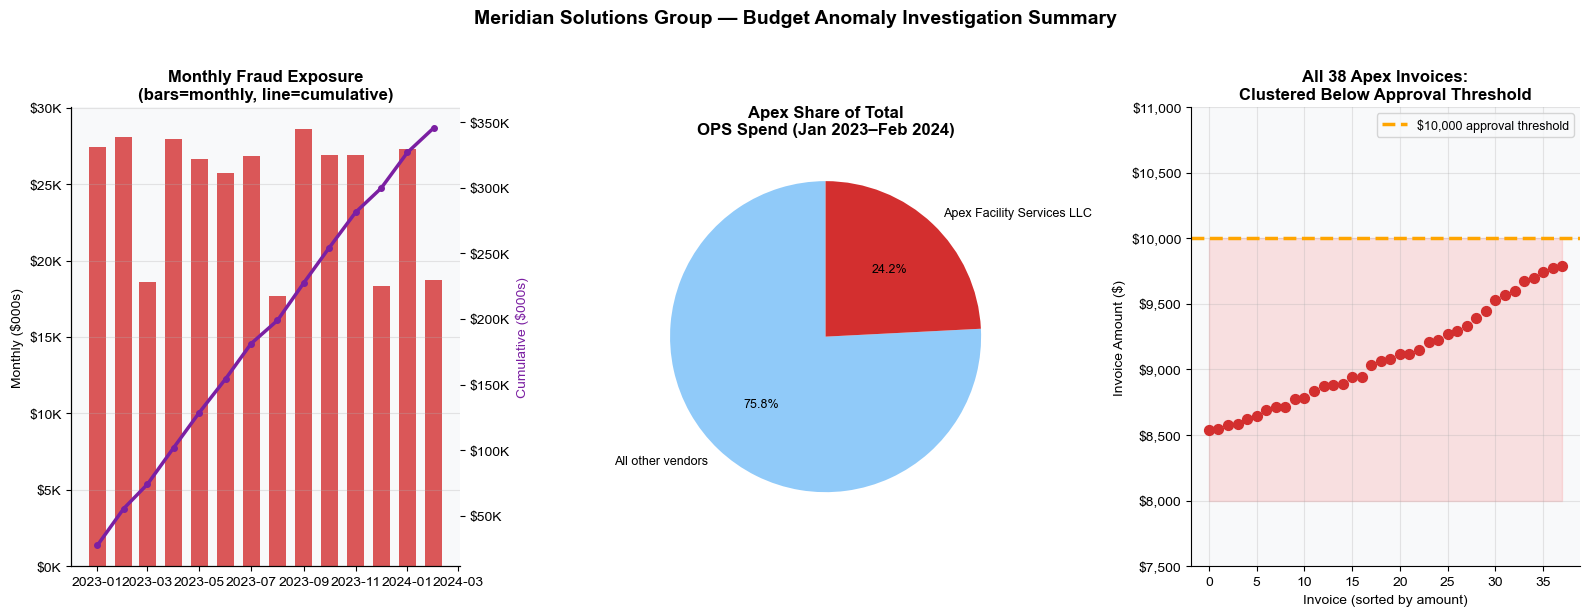

Summary chart saved.

Total estimated exposure: $345,637.32
Investigation complete. Report ready for escalation.


In [13]:
# Final summary visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.suptitle('Meridian Solutions Group — Budget Anomaly Investigation Summary',
             fontsize=14, fontweight='bold', y=1.02)

# Chart 1: Monthly fraud cumulative
monthly_fraud = apex_txns.groupby('Month')['Amount'].sum().reset_index()
monthly_fraud['Cumulative'] = monthly_fraud['Amount'].cumsum()
axes[0].bar(monthly_fraud['Month'], monthly_fraud['Amount'] / 1000,
            color='#D32F2F', alpha=0.8, width=20)
ax2 = axes[0].twinx()
ax2.plot(monthly_fraud['Month'], monthly_fraud['Cumulative'] / 1000,
         color='#7B1FA2', linewidth=2.5, marker='o', markersize=4)
axes[0].set_title('Monthly Fraud Exposure\n(bars=monthly, line=cumulative)', fontweight='bold')
axes[0].set_ylabel('Monthly ($000s)')
ax2.set_ylabel('Cumulative ($000s)', color='#7B1FA2')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:.0f}K'))
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:.0f}K'))
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: Vendor share of OPS spend
vendor_pie = vendor_breakdown.copy()
vendor_pie.loc[vendor_pie['Vendor_Name'] != 'Apex Facility Services LLC', 'Vendor_Name'] = 'All other vendors'
vendor_pie = vendor_pie.groupby('Vendor_Name')['Total_Spend'].sum().reset_index()
colors_pie = ['#D32F2F' if 'Apex' in v else '#90CAF9' for v in vendor_pie['Vendor_Name']]
wedges, texts, autotexts = axes[1].pie(
    vendor_pie['Total_Spend'], labels=vendor_pie['Vendor_Name'],
    colors=colors_pie, autopct='%1.1f%%', startangle=90,
    textprops={'fontsize': 9})
axes[1].set_title('Apex Share of Total\nOPS Spend (Jan 2023–Feb 2024)', fontweight='bold')

# Chart 3: Invoice clustering below threshold
axes[2].scatter(range(len(apex_txns)), sorted(apex_txns['Amount']),
                color='#D32F2F', s=50, zorder=5)
axes[2].axhline(y=10000, color='orange', linewidth=2.5, linestyle='--',
                label='$10,000 approval threshold')
axes[2].fill_between(range(len(apex_txns)), 8000, 10000, alpha=0.1, color='red')
axes[2].set_ylim(7500, 11000)
axes[2].set_xlabel('Invoice (sorted by amount)')
axes[2].set_ylabel('Invoice Amount ($)')
axes[2].set_title('All 38 Apex Invoices:\nClustered Below Approval Threshold', fontweight='bold')
axes[2].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('chart_04_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print('Summary chart saved.')
print()
print(f'Total estimated exposure: ${total_exposure:,.2f}')
print('Investigation complete. Report ready for escalation.')